# BIOT 6900 · Module 9 — Notebook 2
## The real workflow: from notes to an outcome model
**Week 9 · Part III · walk-through (not graded)**

> **⚠️ SYNTHETIC, MATCHED DEMO WORLD.** The cohort and its notes are invented together so the pipeline has real signal to find. No real patient data appears here. The real version swaps in the MIMIC-IV demo tables and, if you are credentialed, MIMIC-IV-Note; the pipeline is unchanged (see **Using the real data**).

**This is a real step up from the toy.** Notebook 1 was six notes, one matcher, no patients. Here the pipeline grows up in five ways:
1. **Entity normalization** — synonyms and abbreviations (AMS, norepinephrine, CMO) collapse to one concept.
2. **A ConText-style assertion engine** — negation, *post*-negation, *pseudo*-negation, experiencer, historical, and hypothetical, not just one trigger scan.
3. **Multiple notes per patient** over a short timeline (admission → progress → discharge), aggregated.
4. **A properly evaluated model** — missing-lab imputation, cross-validation, two model families.
5. **A text model** whose top tokens expose the leakage straight from the raw words.

It still runs anywhere: the model path uses only `pandas` + `scikit-learn`. `Kernel → Restart & Run All`.

## Setup

In [30]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)

def _have(m):
    try: __import__(m); return True
    except Exception: return False
TOOLS = {m: _have(m) for m in ["spacy", "scispacy", "negspacy"]}
print("Real clinical-NLP tools available:", TOOLS, "(all False is fine; the model path is self-contained)")

Real clinical-NLP tools available: {'spacy': True, 'scispacy': True, 'negspacy': True} (all False is fine; the model path is self-contained)


## 1. A ConText-style assertion engine
The toy had one rule: a trigger before the term means negated. Real clinical text needs more. This engine returns **present, absent, historical, family, or hypothetical**, and it handles *post*-negation (“sepsis ruled out”), *pseudo*-negation (“no change” is not a negation), the experiencer (family history), and hypotheticals (“monitor for sepsis”). This is the standard ConText algorithm in miniature.

In [31]:
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved", "not present"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative", "no interval"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic", "years ago"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "in case", "monitor for"]

def sentences(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]

def assertion(term, text):
    """ConText-lite: present | absent | historical | family | hypothetical | None."""
    for sent in sentences(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)   # word boundary: 'mi' won't match 'admitted'
        if not m:
            continue
        pos = m.start()
        pseudo = any(p in low for p in PSEUDO)
        pre  = low[max(0, pos - 60):pos]
        post = low[pos + len(term): pos + len(term) + 45]
        if any(x in low for x in FAM):                                   return "family"
        if any(x in pre for x in HYPO):                                  return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)):
            return "absent"
        if any(x in pre for x in HIST):                                  return "historical"
        return "present"
    return None

# prove it handles cases the toy could not
demo = [
    "No evidence of sepsis.", "Sepsis ruled out this morning.", "No change in sepsis picture.",
    "Mother with history of sepsis.", "History of sepsis last year.", "Will monitor for sepsis.",
    "Clinical picture concerning for sepsis.",
]
for s in demo:
    print(f"  {str(assertion('sepsis', s)):12s} <- {s}")

  absent       <- No evidence of sepsis.
  absent       <- Sepsis ruled out this morning.
  present      <- No change in sepsis picture.
  family       <- Mother with history of sepsis.
  historical   <- History of sepsis last year.
  hypothetical <- Will monitor for sepsis.
  present      <- Clinical picture concerning for sepsis.


## 2. Entity normalization
The identifier problem from lecture, now in code: one concept wears many surface forms. We map each to a canonical key, so “AMS”, “encephalopathy”, and “altered mental status” all count as one feature. Three of these concepts are **consequences of a bad outcome** (pressors, comfort care, intubation): remember them.

In [32]:
SYN = {
    "sepsis":                ["sepsis", "septic", "septic shock", "bacteremia"],
    "altered_mental_status": ["altered mental status", "ams", "encephalopathy", "delirium", "confusion"],
    "acute_kidney_injury":   ["acute kidney injury", "aki", "renal failure"],
    "pressors":              ["pressors", "pressor", "norepinephrine", "levophed", "vasopressors"],   # consequence
    "comfort_care":          ["comfort care", "comfort measures", "cmo", "hospice"],                  # consequence
    "intubation":            ["intubated", "mechanical ventilation", "on the vent", "intubation"],    # consequence
    "myocardial_infarction": ["myocardial infarction", "nstemi", "stemi", "mi"],
}

def concept_present(concept, note_texts):
    """1 if ANY surface form of the concept is asserted PRESENT in ANY of the patient's notes."""
    for variant in SYN[concept]:
        for t in note_texts:
            if assertion(variant, t) == "present":
                return 1
    return 0

print("concepts:", list(SYN))

concepts: ['sepsis', 'altered_mental_status', 'acute_kidney_injury', 'pressors', 'comfort_care', 'intubation', 'myocardial_infarction']


## 3. A cohort with a note trajectory
Each patient gets three notes over time: admission, a day-2 progress note, and a discharge/final note. Genuine risk (sepsis, AMS, AKI, lactate) shows up early. For patients who die, the **consequences** appear in the later notes. That ordering is what creates the leakage we will expose.

In [33]:
N = 400
age = rng.integers(40, 92, N)
sex = rng.choice(["M", "F"], N)
lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14)
creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
sepsis = rng.random(N) < 0.25
ams    = rng.random(N) < 0.20
aki    = rng.random(N) < 0.18
logit = (-2.6 + 0.045*(age-65) + 0.55*(lactate-2) + 1.3*sepsis + 0.9*ams + 0.7*aki + 0.3*(creatinine-1))
died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)

# realistic missingness in labs
lactate_obs = lactate.copy(); lactate_obs[rng.random(N) < 0.15] = np.nan
creat_obs   = creatinine.copy(); creat_obs[rng.random(N) < 0.10] = np.nan

def patient_notes(i):
    adm = [f"{age[i]}{sex[i]} admitted to the ICU."]
    if sepsis[i]: adm.append(rng.choice(["Septic shock, pressors considered.", "Concerning for sepsis; cultures sent."]))
    elif rng.random() < 0.30: adm.append("No evidence of sepsis on initial workup.")   # negated
    if aki[i]: adm.append(rng.choice(["Acute kidney injury on admission.", "Rising creatinine, AKI."]))
    if rng.random() < 0.20: adm.append("History of MI, no acute chest pain.")           # historical + negated
    prog = ["Progress note, hospital day 2."]
    if ams[i]: prog.append(rng.choice(["Altered mental status overnight.", "Increasing confusion, delirium."]))
    if rng.random() < 0.15: prog.append("Family history of CVA.")                       # experiencer noise
    disch = ["Discharge / final note."]
    if died[i]:
        if rng.random() < 0.85: disch.append(rng.choice(["Started on norepinephrine for hypotension.", "Escalating pressors."]))
        if rng.random() < 0.60: disch.append(rng.choice(["Transitioned to comfort care.", "Family elected CMO."]))
        if rng.random() < 0.55: disch.append("Intubated and mechanically ventilated.")
    else:
        if rng.random() < 0.10: disch.append("Brief pressors intraop, weaned.")
        if rng.random() < 0.08: disch.append("Intubated for elective case, extubated.")
        disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge home."]))
    return [" ".join(adm), " ".join(prog), " ".join(disch)]

NOTES = [patient_notes(i) for i in range(N)]
print("#"*70)
print(f"# SYNTHETIC cohort: {N} patients, 3 notes each. Mortality prevalence = {died.mean():.2f}")
print("#"*70)
for d, t in zip(["admit  ", "day 2  ", "final  "], NOTES[0]):
    print(f"  [{d}] {t}")

######################################################################
# SYNTHETIC cohort: 400 patients, 3 notes each. Mortality prevalence = 0.20
######################################################################
  [admit  ] 46F admitted to the ICU. No evidence of sepsis on initial workup.
  [day 2  ] Progress note, hospital day 2.
  [final  ] Discharge / final note. Tolerating diet, ambulating.


## 4. Extract concept features across the trajectory
For each concept, check every surface form in every note with the ConText engine. A concept counts only if it is asserted **present** somewhere in the patient's notes.

In [34]:
CONCEPTS = list(SYN)
feat = pd.DataFrame({"subject_id": np.arange(1, N+1)})
for c in CONCEPTS:
    feat[c] = [concept_present(c, NOTES[i]) for i in range(N)]
print("Patients with each concept asserted PRESENT:")
print(feat[CONCEPTS].sum().to_string())

Patients with each concept asserted PRESENT:
sepsis                    96
altered_mental_status     82
acute_kidney_injury       68
pressors                 134
comfort_care              50
intubation                74
myocardial_infarction      0


`myocardial_infarction = 0`: every MI mention was `history of MI` or negated, so the engine correctly kept it out. A naive matcher would have flagged those patients.

### Assertion-aware vs naive, at scale

In [35]:
def naive_present(concept, note_texts):
    joined = " ".join(note_texts)
    return int(any(re.search(r"\b"+re.escape(v)+r"\b", joined, re.I) for v in SYN[concept]))

naive_sepsis = sum(naive_present("sepsis", NOTES[i]) for i in range(N))
print(f"sepsis   true cause: {int(sepsis.sum())}   naive (any synonym, ignore negation): {naive_sepsis}   assertion-aware: {int(feat['sepsis'].sum())}")
print("Normalization widens the net (more synonyms); assertion narrows it back to the real mentions.")

sepsis   true cause: 96   naive (any synonym, ignore negation): 195   assertion-aware: 96
Normalization widens the net (more synonyms); assertion narrows it back to the real mentions.


## 5. Feature matrix (structured + notes, with missing labs)
Join the note features to the structured fields. Some labs are missing, which we handle with median imputation **inside** the model pipeline so it never peeks at the test fold.

In [36]:
df = feat.copy()
df["age"] = age; df["sex_F"] = (sex == "F").astype(int)
df["lactate"] = lactate_obs; df["creatinine"] = creat_obs
df["died"] = died

struct_cols = ["age", "sex_F", "lactate", "creatinine"]
leak_cols   = ["pressors", "comfort_care", "intubation"]      # consequences of the outcome
all_cols    = struct_cols + CONCEPTS
print(f"missing lactate={df.lactate.isna().sum()}, creatinine={df.creatinine.isna().sum()} (imputed in-pipeline)")
df[["subject_id","age","lactate"]+CONCEPTS+["died"]].head()

missing lactate=59, creatinine=35 (imputed in-pipeline)


,subject_id,age,lactate,sepsis,altered_mental_status,acute_kidney_injury,pressors,comfort_care,intubation,myocardial_infarction,died
0,1,46,0.552987,0,0,0,0,0,0,0,0
1,2,46,1.426912,1,0,1,0,0,0,0,0
2,3,81,2.076674,0,0,0,0,0,0,0,0
3,4,65,4.280974,0,0,1,1,1,1,0,1
4,5,70,0.500000,0,0,0,1,0,1,0,0


## 6. A properly evaluated outcome model
Predict in-hospital mortality. Because deaths are uncommon, accuracy is misleading, so we use **cross-validated AUROC** across 5 folds, for two model families, with and without the leaky features.

In [37]:
def cv_auc(cols, model):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

print("5-fold cross-validated AUROC:")
for name, model in [("logistic", LogisticRegression(max_iter=1000)),
                    ("hist-gbm", HistGradientBoostingClassifier(random_state=0))]:
    m, sd   = cv_auc(all_cols, model)
    mh, sdh = cv_auc([c for c in all_cols if c not in leak_cols], model)
    print(f"  {name:9s}  all features = {m:.3f} ± {sd:.3f}     leakage removed = {mh:.3f} ± {sdh:.3f}")

5-fold cross-validated AUROC:
  logistic   all features = 0.964 ± 0.014     leakage removed = 0.733 ± 0.054
  hist-gbm   all features = 0.944 ± 0.030     leakage removed = 0.622 ± 0.048


Both models score far higher with the leaky features in. That gap is the warning sign.

## 7. Permutation importance, and the leakage lesson
Instead of reading raw coefficients, we measure how much AUROC **drops when each feature is shuffled** on held-out data. This is the 40%.

In [38]:
X, y = df[all_cols].values, df["died"].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                     LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
imp = pd.Series(pi.importances_mean, index=all_cols).sort_values(ascending=False)
print(imp.round(3).to_string())

comfort_care             0.067
intubation               0.063
pressors                 0.054
sepsis                   0.009
altered_mental_status    0.006
lactate                  0.004
sex_F                    0.003
acute_kidney_injury      0.001
creatinine               0.001
myocardial_infarction    0.000
age                     -0.004


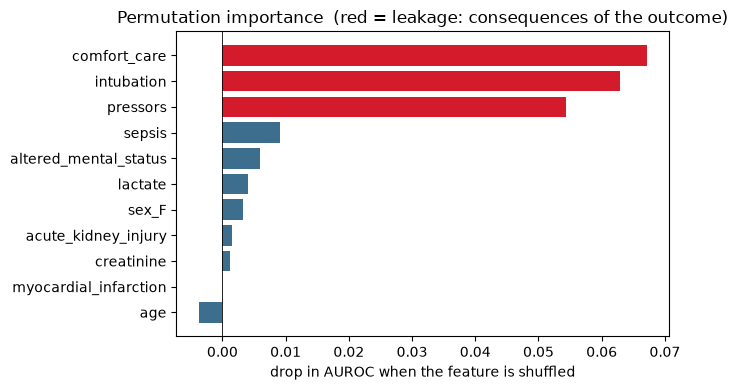

In [39]:
order = imp.sort_values()
colors = ["#D41B2C" if c in leak_cols else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7, 4))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = leakage: consequences of the outcome)")
plt.xlabel("drop in AUROC when the feature is shuffled")
plt.tight_layout(); plt.show()

The top features are **comfort care, intubation, pressors** — things done to a patient who is *already* dying. The model did not foresee the outcome; it read it back from its consequences. That is **label leakage**: a feature can predict perfectly and still be worthless because it is caused by the outcome rather than preceding it.

## 8. The leakage is in the raw words too
What if we skip feature engineering and let a model read the notes directly? A TF-IDF model over the raw text. Watch the score, and watch which tokens it leans on.

In [40]:
corpus = [" ".join(NOTES[i]) for i in range(N)]
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=4, stop_words="english")
Xtx = vec.fit_transform(corpus)
auc = cross_val_score(LogisticRegression(max_iter=1000), Xtx, died,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
lr = LogisticRegression(max_iter=1000).fit(Xtx, died)
terms = np.array(vec.get_feature_names_out())
top = terms[np.argsort(lr.coef_[0])[-10:]][::-1]
print(f"TF-IDF text model: CV AUROC = {auc.mean():.3f}")
print("top tokens pushing toward 'died':", list(top))

TF-IDF text model: CV AUROC = 0.999
top tokens pushing toward 'died': ['escalating', 'note escalating', 'escalating pressors', 'intubated mechanically', 'mechanically', 'mechanically ventilated', 'ventilated', 'note started', 'norepinephrine', 'norepinephrine hypotension']


A near-perfect AUROC should make you suspicious, not proud. The top tokens are *norepinephrine, intubated, mechanically ventilated, comfort* — the vocabulary of dying, not of predicting death. The text model found the same leakage, faster. **A score that looks too good to be true usually is.**

## Optional preview — the real tools on a note
On real notes, scispaCy, negspaCy, and Med7 replace the hand-rolled engine. They skip cleanly here if not installed.

In [41]:
sample = "Started on norepinephrine. No evidence of sepsis. H/o MI."
try:
    import spacy
    from negspacy.negation import Negex
    nlp = spacy.load("en_core_sci_sm"); nlp.add_pipe("negex")
    doc = nlp(sample)
    for e in doc.ents:
        print(f"{e.text:24s} negated={e._.negex}")
except Exception as ex:
    print("[optional] real tools not installed here (" + type(ex).__name__ + ").")
    print("Install (Notebook-2 setup): pip install scispacy negspacy + the scispaCy model wheel, and Med7.")

Started                  negated=False
norepinephrine           negated=False
sepsis                   negated=True
MI                       negated=False


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_core_sci_sm' (0.5.4) was trained with spaCy v3.7.4 and may not be 100% compatible with the current version (3.8.18). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


## Using the real data, scope, and what's next
**Real data.** Structured: the open MIMIC-IV demo (`patients`, `admissions`; `hospital_expire_flag` is the label). Notes: MIMIC-IV-Note, which needs PhysioNet credentialing. Point the extractor at the real `text` column and nothing else changes.

**Scope.** The open demo is ~100 ICU patients and the notes are credentialed, so every metric here is **illustrative**, not deployable.

**The one idea.** The table says what was *measured*; the note says what was *thought*; and a feature that only restates the outcome is not a finding.

**Notebook 3 (graded)** runs this pipeline on *your own* disease cohort and asks you to defend, feature by feature, which signals are genuine and which are leakage. That judgement is the 40%.